# Đối chiếu luồng phát âm hiện tại và Qwen feedback

Notebook tổng hợp kết quả đã chạy trên L2-Arctic-plus. Nhánh hiện tại là **Whisper small.en cho transcript + wav2vec2-B cho âm vị và bộ so khớp phát âm**. Nhánh thử nghiệm Qwen nhận **cùng chuỗi âm vị wav2vec2-B dự đoán**, rồi sinh phản hồi; Q0 là Qwen gốc, Q1 là Qwen feedback LoRA.

> Đây là hai vai trò khác nhau: điểm B đo phát hiện âm vị trên 900 utterance; điểm Qwen đo sinh phản hồi trên pilot 12 utterance. Không thể so trực tiếp hai F1 này. Qwen không nhận audio thô và Projector feedback P1 chưa được train/đánh giá trong kết quả này. Notebook đọc lại artifact inference đã lưu, không chạy lại model nặng hoặc train.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'data/generated/projector-validation-v1/report/summary.json').exists():
    ROOT = ROOT.parent
ART = ROOT / 'data/generated/projector-validation-v1'
SUMMARY = json.loads((ART / 'report/summary.json').read_text(encoding='utf-8'))

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding='utf-8').splitlines() if line.strip()]

q0 = read_jsonl(ART / 'feedback_cascade_B_Q0/predictions.jsonl')
q1 = read_jsonl(ART / 'feedback_cascade_B_Q1/predictions.jsonl')
b_rows = read_jsonl(ROOT / 'data/generated/cascade-l2arctic-plus-seed42/audio/B/predictions.jsonl')
b_meta = json.loads((ROOT / 'data/generated/cascade-l2arctic-plus-seed42/audio/B/metrics.json').read_text(encoding='utf-8'))
print(f'Đã đọc B: {len(b_rows)} mẫu; Q0: {len(q0)}; Q1: {len(q1)}')
print('Cùng utterance Q0/Q1:', [r['utterance_id'] for r in q0] == [r['utterance_id'] for r in q1])

Đã đọc B: 900 mẫu; Q0: 12; Q1: 12
Cùng utterance Q0/Q1: True


## 1. Luồng hiện tại: wav2vec2-B trên toàn bộ test

,Split,Số mẫu,Phone precision,Phone recall,Phone F1,PER,Word F1,False alarm rate
0,L2-Arctic-plus test,900,48.77%,49.84%,49.30%,16.71%,62.78%,50.16%


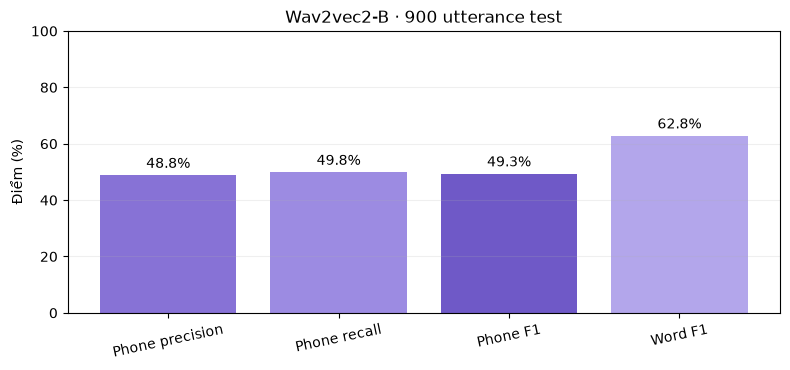

PER = 16.71% (phone error rate). False alarm rate = 50.16%.


In [2]:
m = b_meta['metrics']
current = pd.DataFrame([{
    'Split': 'L2-Arctic-plus test', 'Số mẫu': b_meta['counts']['UTTERANCES'],
    'Phone precision': 100*m['precision'], 'Phone recall': 100*m['recall'],
    'Phone F1': 100*m['f1'], 'PER': 100*m['per'],
    'Word F1': 100*m['word_f1'], 'False alarm rate': 100*m['far'],
}])
display(current.style.format({c: '{:.2f}%' for c in current.columns if c not in ['Split','Số mẫu']}))

fig, ax = plt.subplots(figsize=(8, 3.8))
labels = ['Phone precision', 'Phone recall', 'Phone F1', 'Word F1']
values = [100*m[k] for k in ['precision','recall','f1','word_f1']]
bars = ax.bar(labels, values, color=['#8772d6','#9c8be2','#6f59c7','#b3a6eb'])
ax.set_ylim(0, 100); ax.set_ylabel('Điểm (%)'); ax.set_title('Wav2vec2-B · 900 utterance test')
ax.bar_label(bars, fmt='%.1f%%', padding=3); ax.grid(axis='y', alpha=.2)
plt.xticks(rotation=12); plt.tight_layout(); plt.show()
print(f"PER = {100*m['per']:.2f}% (phone error rate). False alarm rate = {100*m['far']:.2f}%.")

## 2. Qwen: cùng đầu vào âm vị B, Qwen gốc và LoRA

Các chỉ số dưới đây tính trên **12 mẫu pilot**, gồm 2 mẫu cho mỗi người nói. Tất cả 12 mẫu đều có nhãn lỗi tham chiếu; pilot này chưa đo tỷ lệ báo nhầm trên câu phát âm đúng.

,Model,Số mẫu,JSON hợp lệ (%),JSON bám từ mẫu (%),Precision từ (%),Recall từ (%),F1 từ (%),Latency median (s),Latency p95 (s)
0,Qwen gốc (Q0),12,0.0,0.0,0.0,0.0,0.0,13.6,25.1
1,Qwen feedback LoRA (Q1),12,100.0,100.0,65.0,60.5,62.7,14.3,25.3


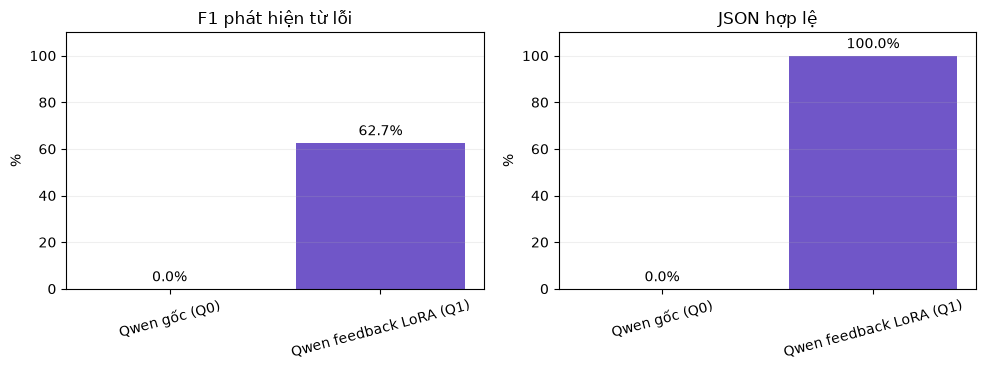

In [3]:
pilot = pd.DataFrame([r for r in SUMMARY['feedback_generation_pilot'] if r['case'] in ['feedback_cascade_B_Q0','feedback_cascade_B_Q1']])
pilot['Model'] = pilot['case'].map({'feedback_cascade_B_Q0':'Qwen gốc (Q0)', 'feedback_cascade_B_Q1':'Qwen feedback LoRA (Q1)'})
pilot = pilot.set_index('Model').loc[['Qwen gốc (Q0)','Qwen feedback LoRA (Q1)']].reset_index()
cols = ['Model','rows','json_valid_percent','grounded_json_percent','feedback_word_precision_percent','feedback_word_recall_percent','feedback_word_f1_percent','latency_median_sec','latency_p95_sec']
display(pilot[cols].rename(columns={
    'rows':'Số mẫu','json_valid_percent':'JSON hợp lệ (%)','grounded_json_percent':'JSON bám từ mẫu (%)',
    'feedback_word_precision_percent':'Precision từ (%)','feedback_word_recall_percent':'Recall từ (%)',
    'feedback_word_f1_percent':'F1 từ (%)','latency_median_sec':'Latency median (s)','latency_p95_sec':'Latency p95 (s)'
}).style.format({c:'{:.1f}' for c in ['JSON hợp lệ (%)','JSON bám từ mẫu (%)','Precision từ (%)','Recall từ (%)','F1 từ (%)','Latency median (s)','Latency p95 (s)']}))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, key, title in [(axes[0], 'feedback_word_f1_percent', 'F1 phát hiện từ lỗi'), (axes[1], 'json_valid_percent', 'JSON hợp lệ')]:
    bars = ax.bar(pilot['Model'], pilot[key], color=['#b7b1c8','#7056c8'])
    ax.set_ylim(0, 110); ax.set_ylabel('%'); ax.set_title(title); ax.bar_label(bars, fmt='%.1f%%', padding=3)
    ax.tick_params(axis='x', rotation=15); ax.grid(axis='y', alpha=.2)
plt.tight_layout(); plt.show()

## 3. Ví dụ đầu ra theo cùng mẫu

Đối chiếu nhãn tham chiếu, kết quả Qwen gốc/Qwen LoRA và âm vị B dự đoán. Âm vị B là đầu vào của hai nhánh Qwen; Qwen không nghe audio trực tiếp ở thí nghiệm này.

In [4]:
q0_by_id = {r['utterance_id']:r for r in q0}
q1_by_id = {r['utterance_id']:r for r in q1}
b_by_id = {r['utterance_id']:r for r in b_rows}
examples = []
for rid in list(q1_by_id)[:4]:
    a, z = q0_by_id[rid], q1_by_id[rid]
    b = b_by_id.get(rid, {})
    examples.append({
        'Utterance': rid, 'B predicted phones': ' '.join(b.get('predicted_phones', [])),
        'Reference feedback': json.dumps(z.get('reference_feedback'), ensure_ascii=False),
        'Qwen gốc': (a.get('raw_text') or '')[:500],
        'Qwen LoRA': json.dumps(z.get('prediction'), ensure_ascii=False),
        'Q0 JSON valid': a.get('valid_json'), 'Q1 JSON valid': z.get('valid_json'),
    })
display(pd.DataFrame(examples).style.set_properties(**{'white-space':'pre-wrap','max-width':'440px'}))

,Utterance,B predicted phones,Reference feedback,Qwen gốc,Qwen LoRA,Q0 JSON valid,Q1 JSON valid
0,NJS/arctic_a0054,D EH R W AH S N AH TH IH N AA N D AH R AA K,"{""there"": [{""issue"": ""\""DH\"" was replaced with \""D\"", indicating a substitution error"", ""suggestion"": ""Strengthen the articulation of /DH/ by comparing it with /D/ in words like \""THIS\"" (/DH IH S/) vs. \""DIS\"" (/D IH S/)""}], ""was"": [{""issue"": ""\""Z\"" was replaced with \""S\"", indicating a consonant substitution"", ""suggestion"": ""Practice voicing with /Z/ versus /S/ using words like \""BUZZ\"" (/B AH Z/) vs. \""BUS\"" (/B AH S/)""}], ""nothing"": [{""issue"": ""\""NG\"" was replaced with \""N\"", indicating a substitution error"", ""suggestion"": ""Practice the velar nasal /NG/ using minimal pairs like \""SING\"" (/S IH NG/) vs. \""SIN\"" (/S IH N/)""}]}","```json { ""affected_word"": [ { ""issue"": ""The word 'nothing' has a silent 'n' and a phonetic annotation of 'TH' which is incorrect."", ""suggestion"": ""The word 'nothing' should be pronounced as 'nōt-hōn' with the silent 'n' and the 'th' sound."" }, { ""issue"": ""The word 'rock' has a phonetic annotation of 'K' which is incorrect."", ""suggestion"": ""The word 'rock' should be pronounced as 'rōck' with the 'k' sound."" } ] } ```","{""there"": [{""issue"": ""\""DH\"" was replaced with \""D\"", indicating a substitution error"", ""suggestion"": ""Practice the distinction between /DH/ and /D/ with pairs like \""THY\"" (/DH IY/) vs. \""DYE\"" (/D IY/)""}], ""was"": [{""issue"": ""\""Z\"" was replaced with \""S\"", indicating a substitution error"", ""suggestion"": ""Practice the distinction between /Z/ and /S/ with pairs like \""ZOO\"" (/Z UW/) vs. \""SOO\"" (/S UW/)""}], ""nothing"": [{""issue"": ""\""NG\"" was replaced with \""N\"", indicating a substitution error"", ""suggestion"": ""Practice the distinction between /NG/ and /N/ with pairs like \""GON\"" (/G NG/) vs. \""GON\"" (/G N/)""}], ""the"": [{""issue"": ""\""DH\"" was replaced with \""D\"", indicating a substitution error"", ""suggestion"": ""Practice the distinction between /DH/ and /D/ with pairs like \""THE\"" (/DH IY/) vs. \""DIE\"" (/D IY/)""}]}",False,True
1,NJS/arctic_b0150,EH N D HH IY W AH S F EH L T W IH DH AH S T R EY N JH EH N F AO R B AA D IH N F IH R,"{""was"": [{""issue"": ""\""Z\"" was replaced with \""S\"", indicating a consonant substitution"", ""suggestion"": ""Practice voiced /Z/ versus voiceless /S/ using words like \""ZOO\"" (/Z UW/) vs. \""SUE\"" (/S UW/)""}], ""filled"": [{""issue"": ""\""IH\"" was replaced with \""EH\"", indicating a vowel substitution"", ""suggestion"": ""Practice /IH/ and /EH/ distinction using pairs like \""FILL\"" (/F IH L/) vs. \""FELL\"" (/F EH L/)""}], ""strange"": [{""issue"": ""\""JH\"" was replaced with \""CH\"", indicating a consonant substitution"", ""suggestion"": ""Practice voiced /JH/ versus voiceless /CH/ using pairs like \""JAM\"" (/JH AE M/) vs. \""CHAM\"" (/CH AE M/)""}], ""foreboding"": [{""issue"": ""\""OW\"" was replaced with \""AO\"", indicating a vowel substitution"", ""suggestion"": ""Practice diphthongs /OW/ and /AO/ using pairs like \""BOW\"" (/B OW/) vs. \""BOUGHT\"" (/B AO T/)""}]}","```json { ""affected_word"": [ { ""issue"": ""The word 'strange' has an incorrect pronunciation with an 'R' instead of 'N' and 'JH'."", ""suggestion"": ""The correct pronunciation is 'strange' with an 'N' and 'JH'."" }, { ""issue"": ""The word 'foreboding' has an incorrect pronunciation with an 'B' instead of 'OW' and 'B'."", ""suggestion"": ""The correct pronunciation is 'foreboding' with an 'B' and 'OW'."" }, { ""issue"": ""The word 'filled' has an incorrect pron","{""and"": [{""issue"": ""\""AE\"" was replaced with \""EH\"", indicating a substitution error"", ""suggestion"": ""Practice the distinction between /AE/ and /EH/ with pairs like \""BUT\"" (/B AE T/) vs. \""BET\"" (/B EH T/)""}], ""was"": [{""issue"": ""\""Z\"" was replaced with \""S\"", indicating a substitution err

## Kết luận và giới hạn

- Luồng âm học hiện tại: wav2vec2-B đạt **49.30% phone F1** và **16.71% PER** trên 900 mẫu test theo scoring protocol của dự án. Đây là số liệu phát hiện âm vị, không phải chất lượng hội thoại.
- Trong pilot cùng đầu vào B, Qwen feedback LoRA tăng **word F1 từ 0% lên 62.65%** và JSON hợp lệ từ **0% lên 100%** so với Qwen gốc. Median generation latency của Q1 là **14.32 giây**.
- Qwen LoRA đang diễn giải/định dạng lỗi từ chuỗi âm vị mà B cung cấp; nó không tự sửa được âm vị sai của B và kết quả không chứng minh Qwen tốt hơn bộ chấm âm học.
- Chỉ 12 utterance, toàn bộ đều có lỗi tham chiếu; feedback train được giám sát bằng nhãn do tác giả sinh với GPT-4o, không phải tất cả đều được chuyên gia kiểm duyệt riêng. Cần đánh giá lớn hơn và có mẫu phát âm đúng để đo false alarms trước khi kết luận khả năng triển khai.